In [170]:
import os
HOME = os.getcwd()
print('HOME :', HOME)

HOME : /home/dbtproject/barsha/np_code_new


In [171]:
!pip install 'git+https://github.com/facebookresearch/segment-anything.git'

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-wqkbaoqo
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-wqkbaoqo


  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [172]:
import pandas as pd
import os
import cv2
import torch
import torchvision
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Dataset,  WeightedRandomSampler
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from torchvision import models

In [173]:
!pip install opencv-python

In [174]:
!pip install supervision


In [175]:
# %cd {HOME}
# !mkdir {HOME}/weights
# %cd {HOME}/weights

# !wget https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth
# !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
# !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_l_0b3195.pth


In [176]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)


cuda:0


In [177]:
%cd {HOME}
!mkdir {HOME}/weights
%cd {HOME}/weights

!wget -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth
!wget -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
!wget -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_l_0b3195.pth


/home/dbtproject/barsha/np_code_new
mkdir: cannot create directory ‘/home/dbtproject/barsha/np_code_new/weights’: File exists
/home/dbtproject/barsha/np_code_new/weights
File ‘sam_vit_h_4b8939.pth’ already there; not retrieving.



File ‘sam_vit_b_01ec64.pth’ already there; not retrieving.

File ‘sam_vit_l_0b3195.pth’ already there; not retrieving.



In [178]:
%cd {HOME}

Model_type = 'vit_h'
CHECKPOINT_PATH = '/home/dbtproject/barsha/np_code_new/weights/sam_vit_h_4b8939.pth'
print(CHECKPOINT_PATH, "; exist:", os.path.isfile(CHECKPOINT_PATH))

/home/dbtproject/barsha/np_code_new
/home/dbtproject/barsha/np_code_new/weights/sam_vit_h_4b8939.pth ; exist: True


In [179]:
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor
sam = sam_model_registry[Model_type](checkpoint=CHECKPOINT_PATH).to(device=device)

In [180]:
img_path = '/home/dbtproject/barsha/Image/test_set/Class0_Graminicola/Chaibasa_2_PP_7.tiff'
img_bgr = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
original_img = img_bgr
print(img_rgb.shape)

(1920, 2560, 3)


In [181]:
print(img_bgr)

[[[70 70 70]
  [70 70 70]
  [73 73 73]
  ...
  [70 70 70]
  [71 71 71]
  [71 71 71]]

 [[71 71 71]
  [71 71 71]
  [73 73 73]
  ...
  [72 72 72]
  [72 72 72]
  [72 72 72]]

 [[71 71 71]
  [71 71 71]
  [72 72 72]
  ...
  [72 72 72]
  [72 72 72]
  [72 72 72]]

 ...

 [[65 65 65]
  [66 66 66]
  [68 68 68]
  ...
  [65 65 65]
  [64 64 64]
  [64 64 64]]

 [[65 65 65]
  [66 66 66]
  [69 69 69]
  ...
  [64 64 64]
  [64 64 64]
  [65 65 65]]

 [[65 65 65]
  [66 66 66]
  [69 69 69]
  ...
  [64 64 64]
  [64 64 64]
  [65 65 65]]]


In [182]:
# import os

# print(os.path.abspath(img_path))
# print(os.path.exists(img_path))



In [183]:
img_rgb = cv2.resize(img_rgb, (1024,1024), interpolation = None)
img_bgr = cv2.resize(img_bgr, (1024,1024), interpolation = None)
original_img = cv2.resize(original_img, (1024,1024), interpolation = None)
print(img_rgb.shape)

(1024, 1024, 3)


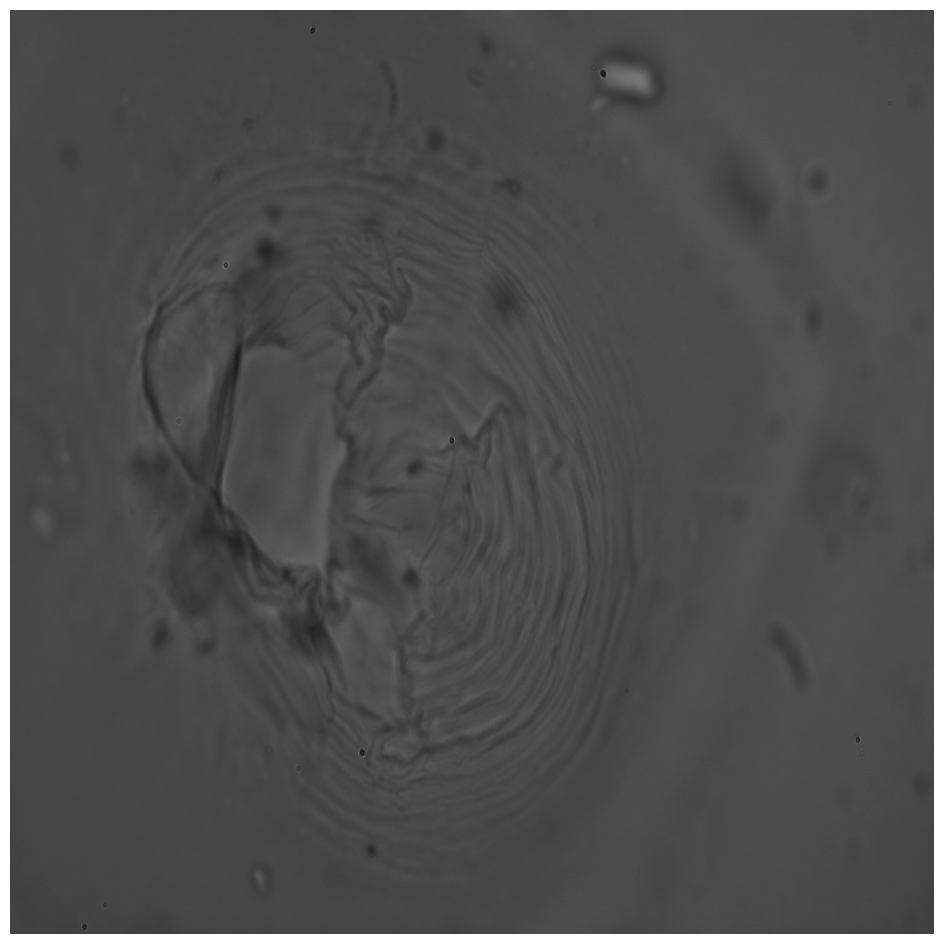

In [184]:
import supervision as sv
sv.plot_image(img_bgr)

In [185]:
mask_generator = SamAutomaticMaskGenerator(sam)
result = mask_generator.generate(img_rgb)
print(result[0].keys())
print(len(result))

dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
27


In [186]:
bboxes = []
points = []
segmentations = []
areas =[]
crop_boxes = []

#understanding the result parameters & all segmentation 

for mask in result :
    bboxes.append(mask['bbox'])
    points.append(mask['point_coords'])
    segmentations.append(mask['segmentation'])
    areas.append(mask['area'])
    crop_boxes.append(mask['crop_box'])

    print(mask['bbox'])

[235.0, 371.0, 136.0, 246.0]
[880.0, 477.0, 83.0, 128.0]
[876.0, 165.0, 38.0, 52.0]
[462.0, 131.0, 19.0, 24.0]
[23.0, 548.0, 25.0, 36.0]
[264.0, 945.0, 26.0, 37.0]
[652.0, 54.0, 66.0, 46.0]
[1001.0, 845.0, 19.0, 25.0]
[506.0, 63.0, 21.0, 23.0]
[935.0, 8.0, 19.0, 26.0]
[879.0, 319.0, 22.0, 41.0]
[796.0, 540.0, 21.0, 24.0]
[156.0, 675.0, 21.0, 33.0]
[777.0, 153.0, 71.0, 93.0]
[993.0, 81.0, 20.0, 28.0]
[649.0, 44.0, 74.0, 59.0]
[841.0, 679.0, 45.0, 74.0]
[999.0, 334.0, 21.0, 24.0]
[838.0, 453.0, 16.0, 18.0]
[520.0, 28.0, 16.0, 20.0]
[272.0, 251.0, 23.0, 29.0]
[331.0, 17.0, 8.0, 10.0]
[332.0, 18.0, 6.0, 9.0]
[749.0, 563.0, 14.0, 28.0]
[903.0, 580.0, 19.0, 26.0]
[409.0, 55.0, 21.0, 63.0]
[128.0, 1000.0, 62.0, 23.0]


In [187]:
#sort all segmenation and their boundary boxes considering the area
segmentations = [segment['segmentation'] for segment in sorted(result, key=lambda x:x['area'], reverse=True)]
bboxes = [bbox['bbox'] for bbox in sorted(result, key=lambda x:x['area'], reverse=True)]
points = [point['point_coords'] for point in sorted(result, key=lambda x:x['area'], reverse=True)]
crop_boxes = [crop['crop_box'] for crop in sorted(result, key=lambda x:x['area'], reverse=True)]


print(bboxes)
print(points)
print(crop_boxes)
print(len(segmentations))

[[235.0, 371.0, 136.0, 246.0], [880.0, 477.0, 83.0, 128.0], [777.0, 153.0, 71.0, 93.0], [649.0, 44.0, 74.0, 59.0], [652.0, 54.0, 66.0, 46.0], [876.0, 165.0, 38.0, 52.0], [841.0, 679.0, 45.0, 74.0], [128.0, 1000.0, 62.0, 23.0], [264.0, 945.0, 26.0, 37.0], [879.0, 319.0, 22.0, 41.0], [409.0, 55.0, 21.0, 63.0], [23.0, 548.0, 25.0, 36.0], [272.0, 251.0, 23.0, 29.0], [156.0, 675.0, 21.0, 33.0], [993.0, 81.0, 20.0, 28.0], [903.0, 580.0, 19.0, 26.0], [999.0, 334.0, 21.0, 24.0], [796.0, 540.0, 21.0, 24.0], [1001.0, 845.0, 19.0, 25.0], [935.0, 8.0, 19.0, 26.0], [462.0, 131.0, 19.0, 24.0], [506.0, 63.0, 21.0, 23.0], [749.0, 563.0, 14.0, 28.0], [520.0, 28.0, 16.0, 20.0], [838.0, 453.0, 16.0, 18.0], [331.0, 17.0, 8.0, 10.0], [332.0, 18.0, 6.0, 9.0]]
[[[240.0, 528.0]], [[912.0, 560.0]], [[848.0, 208.0]], [[720.0, 80.0]], [[688.0, 80.0]], [[880.0, 208.0]], [[848.0, 688.0]], [[144.0, 1008.0]], [[272.0, 944.0]], [[880.0, 336.0]], [[432.0, 112.0]], [[48.0, 560.0]], [[272.0, 272.0]], [[176.0, 688.0]], [

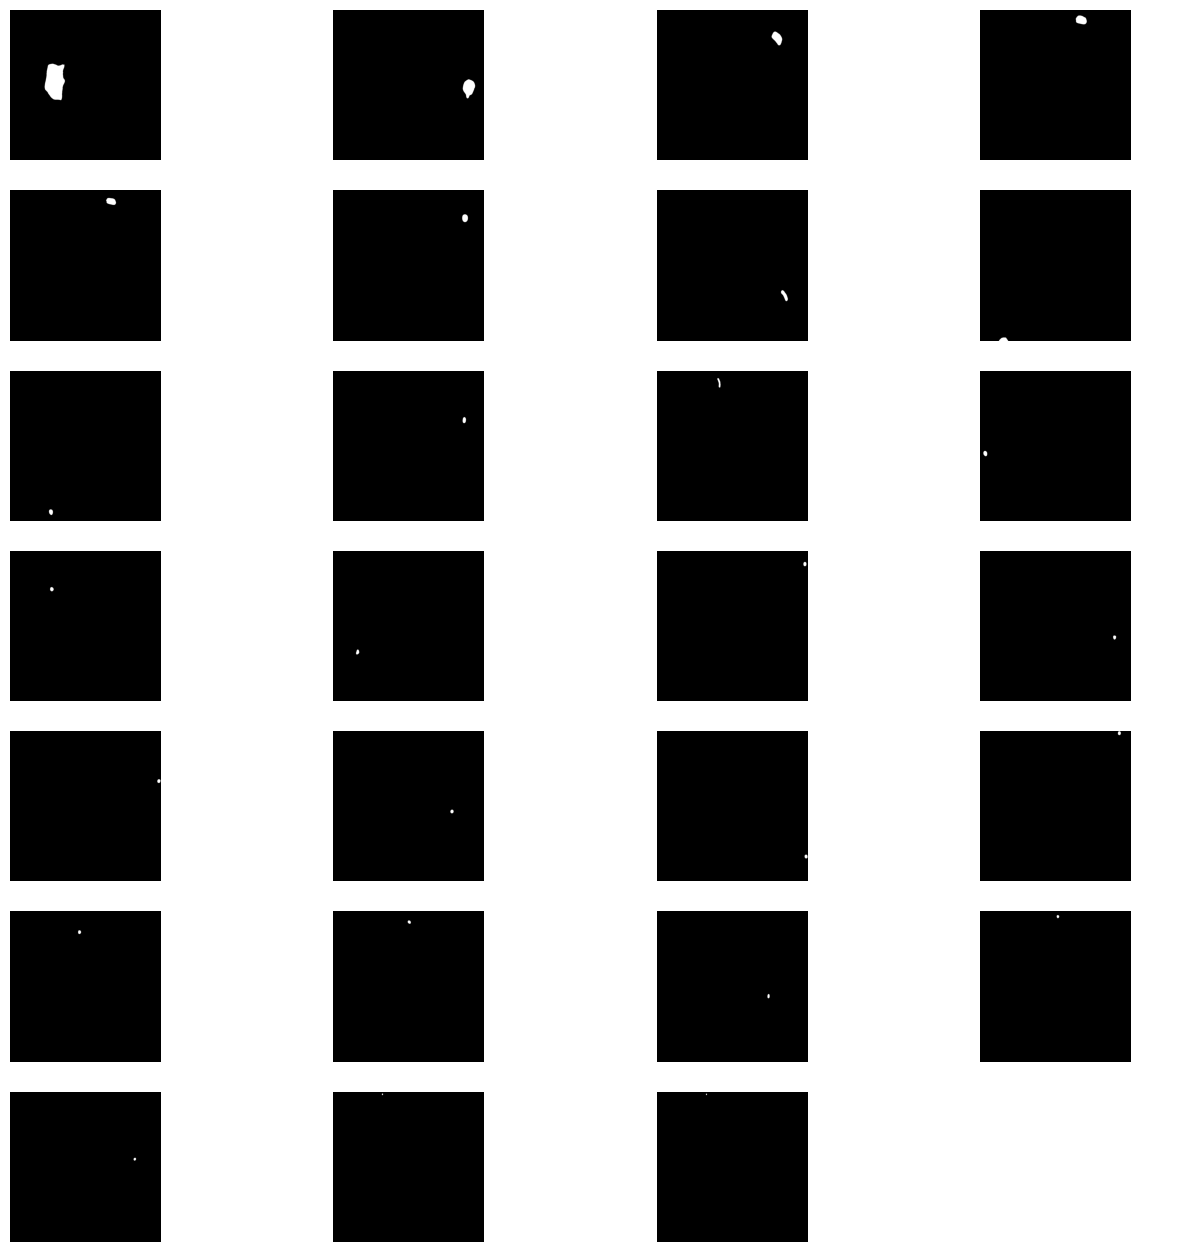

In [188]:
#draw all mask in a grid 
sv.plot_images_grid(images = segmentations,grid_size = (int(len(segmentations)/4+1),4),size = (16,16))


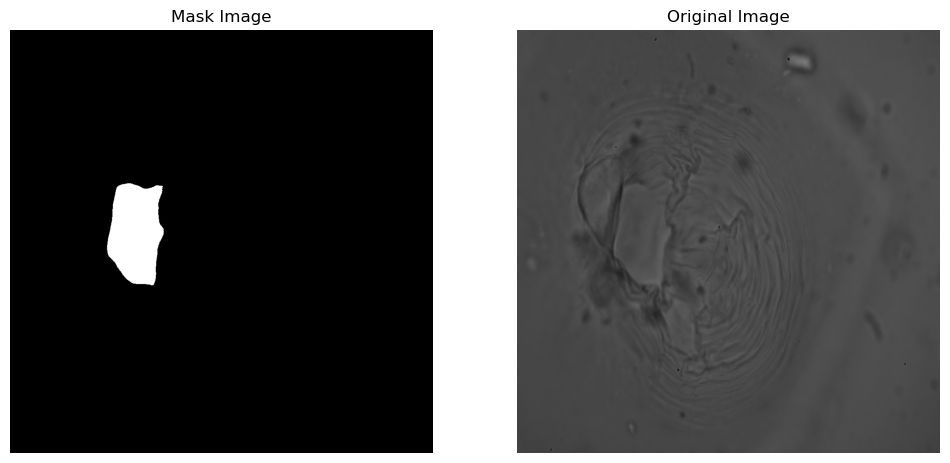

In [189]:
#draw the largest or smallest mask 
sv.plot_images_grid(
    images = [segmentations[0],img_bgr],
    grid_size =(1,2),
    titles = ['Mask Image', 'Original Image']
)

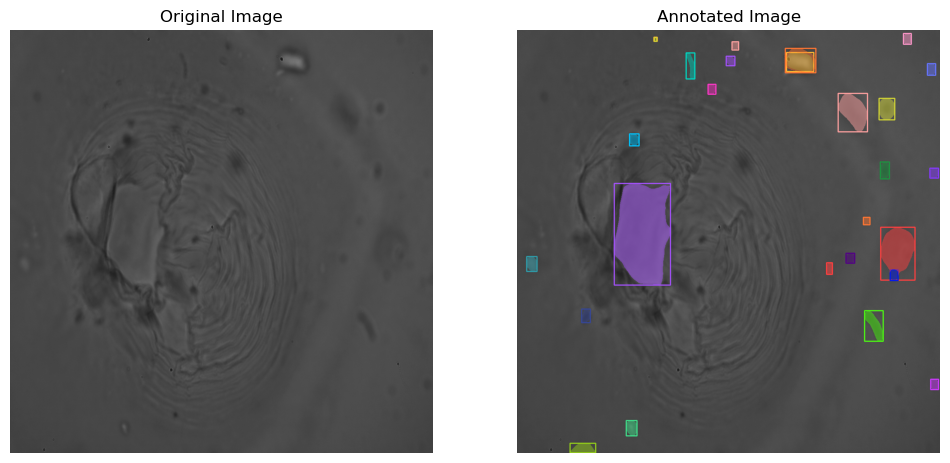

In [190]:
#initialize mask and box annotator
mask_annotator = sv.MaskAnnotator(color_lookup=sv.ColorLookup.INDEX)
box_annotator = sv.BoxAnnotator(
    # color=sv.Color.BLUE,
    color_lookup=sv.ColorLookup.INDEX
)



#for automatic mask generator for all segnmented parts of the image
detections = sv.Detections.from_sam(result)

#for displaying the largest mask
annotated_img = box_annotator.annotate(scene=img_bgr.copy(),detections=detections)
annotated_img = mask_annotator.annotate(scene = annotated_img.copy(),detections=detections)

#display all seg with annotation 
sv.plot_images_grid(
    images = [img_bgr, annotated_img],
    grid_size = (1,2),
    titles = ['Original Image', 'Annotated Image']

)

In [191]:
#draw mask by point co-or & bboxes
sam.to(device)
seg_predictor = SamPredictor(sam)
seg_predictor.set_image(img_rgb)


In [192]:
#generating mask for point co-or

input_point = np.array(points[0])
input_label = np.array([1])

mask_by_point, scores, logits = seg_predictor.predict(
    point_coords = input_point,
    point_labels = input_label,
    multimask_output=False
)

print(len(mask_by_point))

1


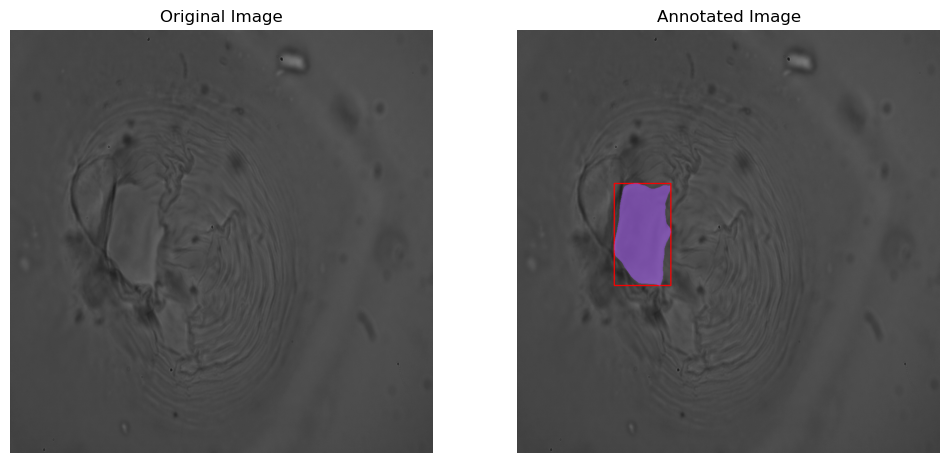

In [193]:
#initialize mask and box annotator
mask_annotator = sv.MaskAnnotator(color_lookup=sv.ColorLookup.INDEX)
box_annotator = sv.BoxAnnotator(
    color=sv.Color.RED,
    color_lookup=sv.ColorLookup.INDEX
)


detections = sv.Detections(xyxy = sv.mask_to_xyxy(masks = mask_by_point),mask = mask_by_point)

#for detection the largest mask
detections = detections[detections.area == np.max(detections.area)]

#for displaying the largest mask
annotated_img = box_annotator.annotate(scene=img_bgr.copy(),detections=detections)
annotated_img = mask_annotator.annotate(scene = annotated_img.copy(),detections=detections)

#display all seg with annotation 
sv.plot_images_grid(
    images = [img_bgr, annotated_img],
    grid_size = (1,2),
    titles = ['Original Image', 'Annotated Image']

)

In [194]:
#generating mask or segmentation for bounding box

x,y,w,h = bboxes[0]
box = np.array([x,y, x+w, y+h])


In [195]:
mask_by_bbox, scores, logits = seg_predictor.predict(
    point_coords=None,
    point_labels=None,
    box=box,
    multimask_output=False
)
print(len(mask_by_bbox))

1


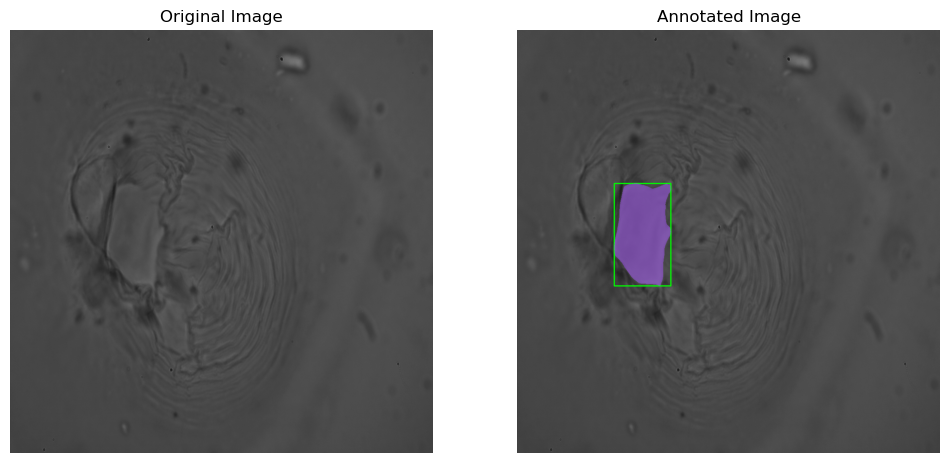

In [196]:
#initialize mask and box annotator
mask_annotator = sv.MaskAnnotator(color_lookup=sv.ColorLookup.INDEX)
box_annotator = sv.BoxAnnotator(
    color=sv.Color.GREEN,
    color_lookup=sv.ColorLookup.INDEX
)

detections = sv.Detections(xyxy = sv.mask_to_xyxy(masks = mask_by_bbox),mask = mask_by_bbox)


#for display the largest mask
# detections = detections[detections.area == np.max(detections.area)]
#for displaying the largest mask
annotated_img = box_annotator.annotate(scene=img_bgr.copy(),detections=detections)
annotated_img = mask_annotator.annotate(scene = annotated_img.copy(),detections=detections)

#display all seg with annotation 
sv.plot_images_grid(
    images = [img_bgr, annotated_img],
    grid_size = (1,2),
    titles = ['Original Image', 'Annotated Image']

)

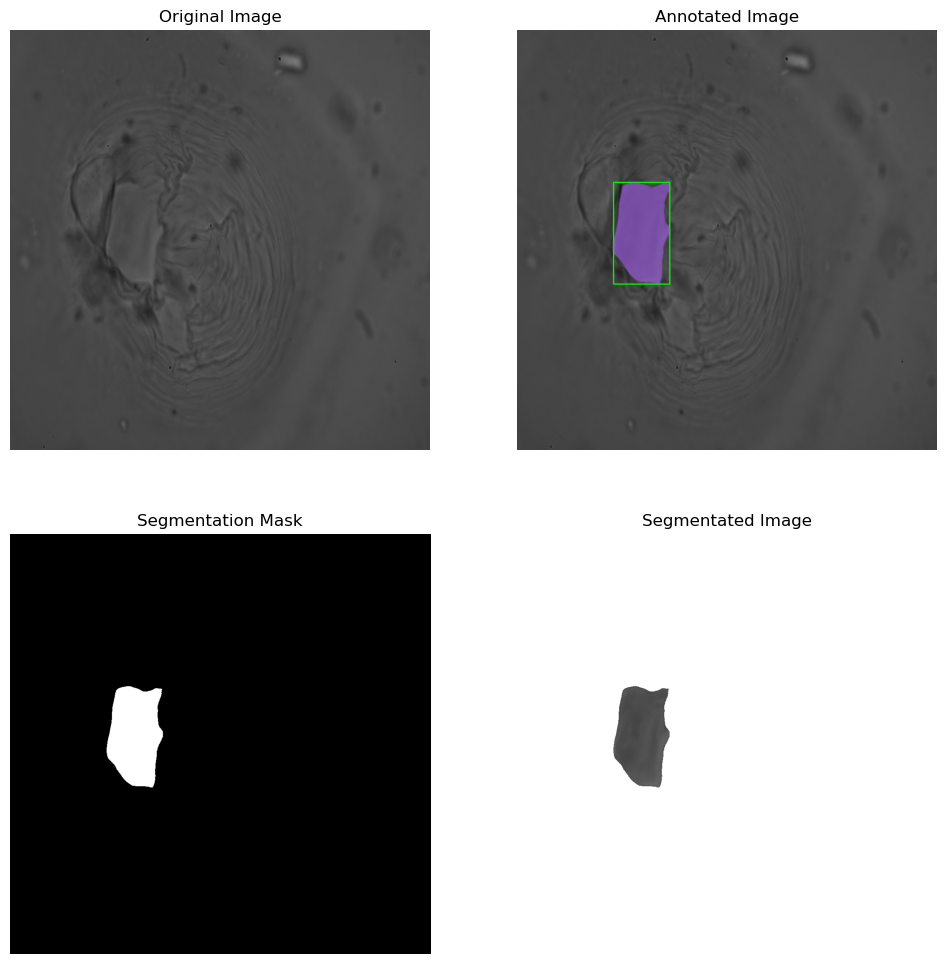

In [197]:

mask_annotator = sv.MaskAnnotator(color_lookup=sv.ColorLookup.INDEX)
box_annotator = sv.BoxAnnotator(
    color=sv.Color.GREEN,
    color_lookup=sv.ColorLookup.INDEX
)

detections = sv.Detections(xyxy = sv.mask_to_xyxy(masks = mask_by_bbox),mask = mask_by_bbox)


#for display the largest mask
detections = detections[detections.area == np.max(detections.area)]


annotated_img = box_annotator.annotate(scene=img_bgr.copy(),detections=detections)
annotated_img = mask_annotator.annotate(scene = annotated_img.copy(),detections=detections)


#for display segmented part of the image in white background


#convert 2D numpy array (large segmentation) to 2D gray scale img
seg_mask = np.array(segmentations[0]*255).astype('uint8')

#convert this gray scale img to BGR img (3D with RGB channel)
seg_img = cv2.cvtColor(seg_mask, cv2.COLOR_GRAY2BGR)

#bitwise operate between converted 3D seg with original BGR img
seg_img1 = cv2.bitwise_and(seg_img, img_bgr)

#make all dark 0 pixel to white pixel (1 or 255)
seg_img1[np.where((seg_img == [0,0,0]).all(axis=2))] = [255,255,255]


#display all seg img with annotation 
sv.plot_images_grid(
    images = [img_bgr, annotated_img, seg_mask, seg_img1],
    grid_size = (2,2),
    titles = ['Original Image', 'Annotated Image', 'Segmentation Mask', 'Segmentated Image']

)